Connected to Python 3.13.0

In [ ]:
#!/usr/bin/env python3
"""
Growth Bacteria Figure
Author: Valentin Goupille
Date: 2025-07-16
"""


# %%
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the working directory to the project root
os.chdir(os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(__file__)))))

In [ ]:
# Read the Excel file without header
df = pd.read_excel("data/meta/plan_exp.xlsx", sheet_name="suivi", header=None)

# Convert the first row values (except the first column) to datetime
df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])

# Get timepoints from the first row
timepoints = df.iloc[0, 1:]

# Remove the first two rows: [0] for dates, [1] for incubations
data = df.iloc[2:, :].copy()

# Rename columns: "Condition" + timepoints converted to list
data.columns = ["Condition"] + list(timepoints)

# Reset index
data = data.reset_index(drop=True)

print(data)

   Condition 2025-03-13 09:45:00 2025-03-13 11:10:00 2025-03-13 12:10:00  \
0      M9F_A               0.039               0.173                0.27   
1      M9F_B               0.066               0.208               0.291   
2      M9F_C               0.068               0.168               0.255   
3       M9_A               0.062                0.13               0.146   
4       M9_B               0.055               0.134               0.145   
5       M9_C               0.059               0.128                0.15   
6        NaN                 NaN                 NaN                 NaN   
7        NaN                 NaN                 NaN                 NaN   
8        NaN                 NaN                 NaN                 NaN   
9        NaN                 NaN                 NaN                 NaN   
10     M9F_A                OD1                19h15                 NaN   
11     M9F_B                OD1                19h15                 NaN   
12     M9F_C

<ipython-input-2-6bfb46155310>:7: UserWarning: Parsing dates in  %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])


In [ ]:
# Convert to long format
data_long = data.melt(id_vars="Condition", var_name="Time", value_name="OD")

# Clean the OD column: remove any non-numeric values and convert to numeric
data_long["OD"] = pd.to_numeric(data_long["OD"], errors="coerce")

# Remove rows with NaN values in OD column
data_long = data_long.dropna(subset=["OD"])

# Display the result
print(data_long)

    Condition                 Time     OD
0       M9F_A  2025-03-13 09:45:00  0.039
1       M9F_B  2025-03-13 09:45:00  0.066
2       M9F_C  2025-03-13 09:45:00  0.068
3        M9_A  2025-03-13 09:45:00  0.062
4        M9_B  2025-03-13 09:45:00  0.055
5        M9_C  2025-03-13 09:45:00  0.059
28      M9F_A  2025-03-13 11:10:00  0.173
29      M9F_B  2025-03-13 11:10:00  0.208
30      M9F_C  2025-03-13 11:10:00  0.168
31       M9_A  2025-03-13 11:10:00  0.130
32       M9_B  2025-03-13 11:10:00  0.134
33       M9_C  2025-03-13 11:10:00  0.128
56      M9F_A  2025-03-13 12:10:00  0.270
57      M9F_B  2025-03-13 12:10:00  0.291
58      M9F_C  2025-03-13 12:10:00  0.255
59       M9_A  2025-03-13 12:10:00  0.146
60       M9_B  2025-03-13 12:10:00  0.145
61       M9_C  2025-03-13 12:10:00  0.150
84      M9F_A  2025-03-13 14:00:00  0.366
85      M9F_B  2025-03-13 14:00:00  0.402
86      M9F_C  2025-03-13 14:00:00  0.329
112     M9F_A  2025-03-13 15:00:00  0.588
113     M9F_B  2025-03-13 15:00:00

In [ ]:
# Define experiment start time
start_time = pd.Timestamp("2025-03-13 09:45:00") - pd.Timedelta(hours=17, minutes=45)

# Ensure Time column is in datetime format
data_long["Time"] = pd.to_datetime(data_long["Time"])

# Calculate incubation time (difference in timedelta)
data_long["Incubation_timedelta"] = data_long["Time"] - start_time

# Keep only positive values (optional, comment this line if needed)
data_long = data_long[data_long["Incubation_timedelta"] >= pd.Timedelta(0)]


# Format as "XXhYY" (hours and minutes)
def format_timedelta(td):
    total_seconds = int(td.total_seconds())
    hours = total_seconds // 3600
    minutes = (total_seconds % 3600) // 60
    return f"{hours}h{minutes:02d}"


data_long["Incubation_t"] = data_long["Incubation_timedelta"].apply(format_timedelta)

# Drop temporary timedelta column
data_long.drop(columns=["Incubation_timedelta"], inplace=True)

print(data_long)

    Condition                Time     OD Incubation_t
0       M9F_A 2025-03-13 09:45:00  0.039        17h45
1       M9F_B 2025-03-13 09:45:00  0.066        17h45
2       M9F_C 2025-03-13 09:45:00  0.068        17h45
3        M9_A 2025-03-13 09:45:00  0.062        17h45
4        M9_B 2025-03-13 09:45:00  0.055        17h45
5        M9_C 2025-03-13 09:45:00  0.059        17h45
28      M9F_A 2025-03-13 11:10:00  0.173        19h10
29      M9F_B 2025-03-13 11:10:00  0.208        19h10
30      M9F_C 2025-03-13 11:10:00  0.168        19h10
31       M9_A 2025-03-13 11:10:00  0.130        19h10
32       M9_B 2025-03-13 11:10:00  0.134        19h10
33       M9_C 2025-03-13 11:10:00  0.128        19h10
56      M9F_A 2025-03-13 12:10:00  0.270        20h10
57      M9F_B 2025-03-13 12:10:00  0.291        20h10
58      M9F_C 2025-03-13 12:10:00  0.255        20h10
59       M9_A 2025-03-13 12:10:00  0.146        20h10
60       M9_B 2025-03-13 12:10:00  0.145        20h10
61       M9_C 2025-03-13 12:

In [ ]:
# Read the file containing ODt values
odt_df = pd.read_excel("data/meta/plan_exp.xlsx", sheet_name="ODt")

print(odt_df)

# Ensure 'Incubation_t' is in string format
odt_df["Incubation_t"] = odt_df["Incubation_t"].astype(str)

# Ensure data_long also has string format
data_long["Incubation_t"] = data_long["Incubation_t"].astype(str)

# Merge the dataframes
merged_df = pd.merge(
    data_long,
    odt_df[["Condition", "Incubation_t", "ODt"]],
    on=["Condition", "Incubation_t"],
    how="left",
).reindex(columns=list(data_long.columns) + ["ODt"])

print(merged_df)

   Condition   ODt Incubation_t
0      M9F_A  OD1         19h10
1      M9F_B  OD1         19h10
2      M9F_C  OD1         19h10
3       M9_A  OD1         19h10
4       M9_B  OD1         19h10
5       M9_C  OD1         19h10
6      M9F_A   OD2        23h00
7      M9F_B   OD2        23h00
8      M9F_C   OD2        23h00
9       M9_A   OD2        26h45
10      M9_B   OD2        26h45
11      M9_C   OD2        26h45
12     M9F_A   OD3        25h30
13     M9F_B   OD3        25h30
14     M9F_C   OD3        25h30
15      M9_A   OD3        42h00
16      M9_B   OD3        42h00
17      M9_C   OD3        42h00
   Condition                Time     OD Incubation_t   ODt
0      M9F_A 2025-03-13 09:45:00  0.039        17h45   NaN
1      M9F_B 2025-03-13 09:45:00  0.066        17h45   NaN
2      M9F_C 2025-03-13 09:45:00  0.068        17h45   NaN
3       M9_A 2025-03-13 09:45:00  0.062        17h45   NaN
4       M9_B 2025-03-13 09:45:00  0.055        17h45   NaN
5       M9_C 2025-03-13 09:45:00  0.05

In [ ]:
# Group by Condition and get unique ODt values
print(merged_df.groupby("Condition")["ODt"].unique())

Condition
M9F_A    [nan, OD1 , OD2, OD3]
M9F_B    [nan, OD1 , OD2, OD3]
M9F_C    [nan, OD1 , OD2, OD3]
M9_A     [nan, OD1 , OD2, OD3]
M9_B     [nan, OD1 , OD2, OD3]
M9_C     [nan, OD1 , OD2, OD3]
Name: ODt, dtype: object


Data types:
Condition                        object
Time                     datetime64[ns]
OD                              float64
Incubation_t                     object
ODt                              object
Incubation_timedelta    timedelta64[ns]
Incubation_hours                float64
dtype: object

OD column unique values (first 20):
[0.039 0.066 0.068 0.062 0.055 0.059 0.173 0.208 0.168 0.13  0.134 0.128
 0.27  0.291 0.255 0.146 0.145 0.15  0.366 0.402]


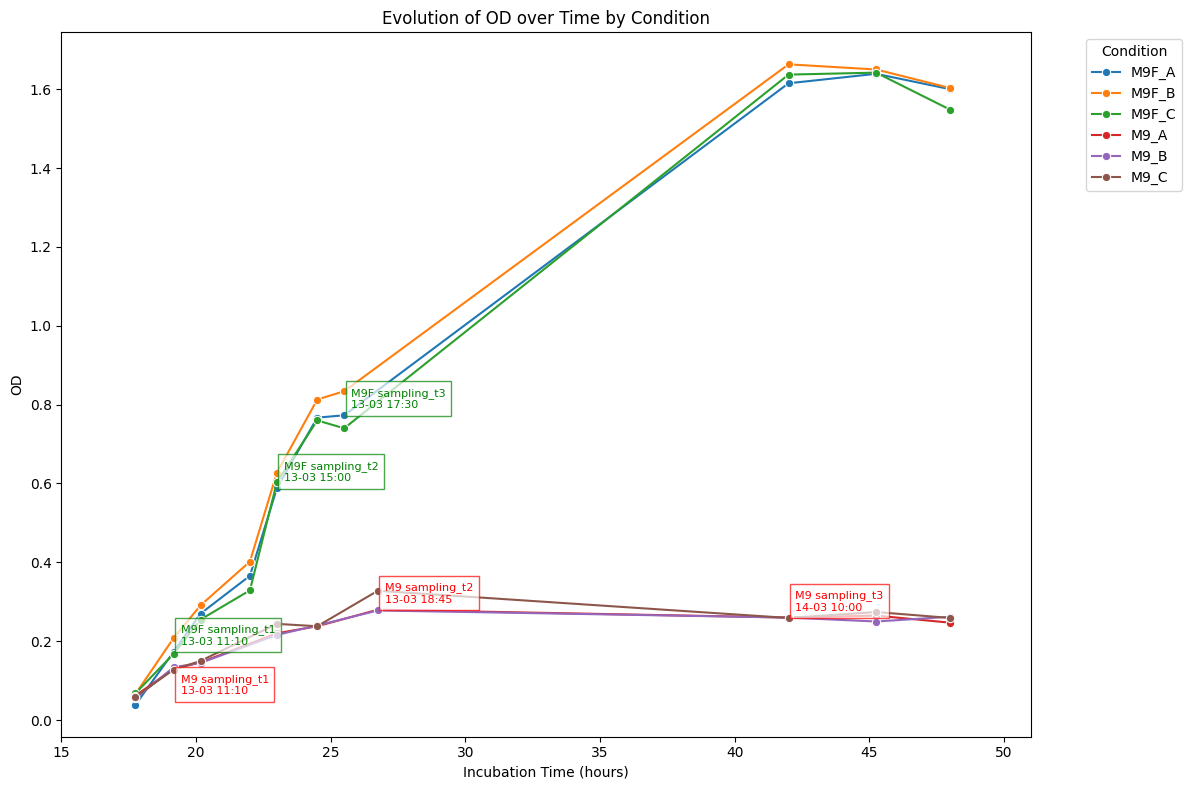

In [ ]:
# Function to convert "XXhYY" to pd.Timedelta
def str_to_timedelta(s):
    try:
        h, m = s.split("h")
        return pd.Timedelta(hours=int(h), minutes=int(m))
    except Exception:
        return pd.NaT  # Return NaT if conversion fails


# Apply conversion to "Incubation_t" column
merged_df["Incubation_timedelta"] = merged_df["Incubation_t"].apply(str_to_timedelta)

# Create numeric column in hours for x-axis
merged_df["Incubation_hours"] = (
    merged_df["Incubation_timedelta"].dt.total_seconds() / 3600
)

# Check for any remaining non-numeric values in OD column
print("Data types:")
print(merged_df.dtypes)
print("\nOD column unique values (first 20):")
print(merged_df["OD"].unique()[:20])

# Ensure OD column is numeric
merged_df["OD"] = pd.to_numeric(merged_df["OD"], errors="coerce")

# Remove any rows with NaN values in critical columns
merged_df = merged_df.dropna(subset=["OD", "Incubation_hours"])

# Create plot with incubation hours
plt.figure(figsize=(12, 8))

# Plot the graph with numeric column and set x-axis limits
sns.lineplot(data=merged_df, x="Incubation_hours", y="OD", hue="Condition", marker="o")
plt.xlim(15, max(merged_df["Incubation_hours"]) + 3)  # Set x-axis range

# Add annotations for points with ODt values but only for M9_A and M9F_A conditions
for idx, row in merged_df[
    (~merged_df["ODt"].isna()) & (merged_df["Condition"].isin(["M9_A", "M9F_A"]))
].iterrows():
    # Set color based on condition
    label_color = "green" if row["Condition"].startswith("M9F") else "red"

    # Map OD values to sampling labels with condition prefix
    od_value = str(row["ODt"]).strip()
    condition_prefix = "M9F" if row["Condition"].startswith("M9F") else "M9"

    if od_value == "OD1":
        sampling_label = f"{condition_prefix} sampling_t1"
    elif od_value == "OD2":
        sampling_label = f"{condition_prefix} sampling_t2"
    elif od_value == "OD3":
        sampling_label = f"{condition_prefix} sampling_t3"
    else:
        sampling_label = str(row["ODt"])

    # Set annotation position
    if sampling_label == "M9 sampling_t1":
        y_pos = 0.03
        xytext = (5, 10)
    else:
        y_pos = row["OD"]
        xytext = (5, 5)

    # Format time as DD-MM HH:MM
    time_str = row["Time"].strftime("%d-%m %H:%M")
    plt.annotate(
        f"{sampling_label}\n{time_str}",
        xy=(row["Incubation_hours"], y_pos),
        xytext=xytext,
        textcoords="offset points",
        fontsize=8,
        color=label_color,
        bbox=dict(facecolor="white", edgecolor=label_color, alpha=0.7),
    )

plt.title("Evolution of OD over Time by Condition")
plt.xlabel("Incubation Time (hours)")
plt.ylabel("OD")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

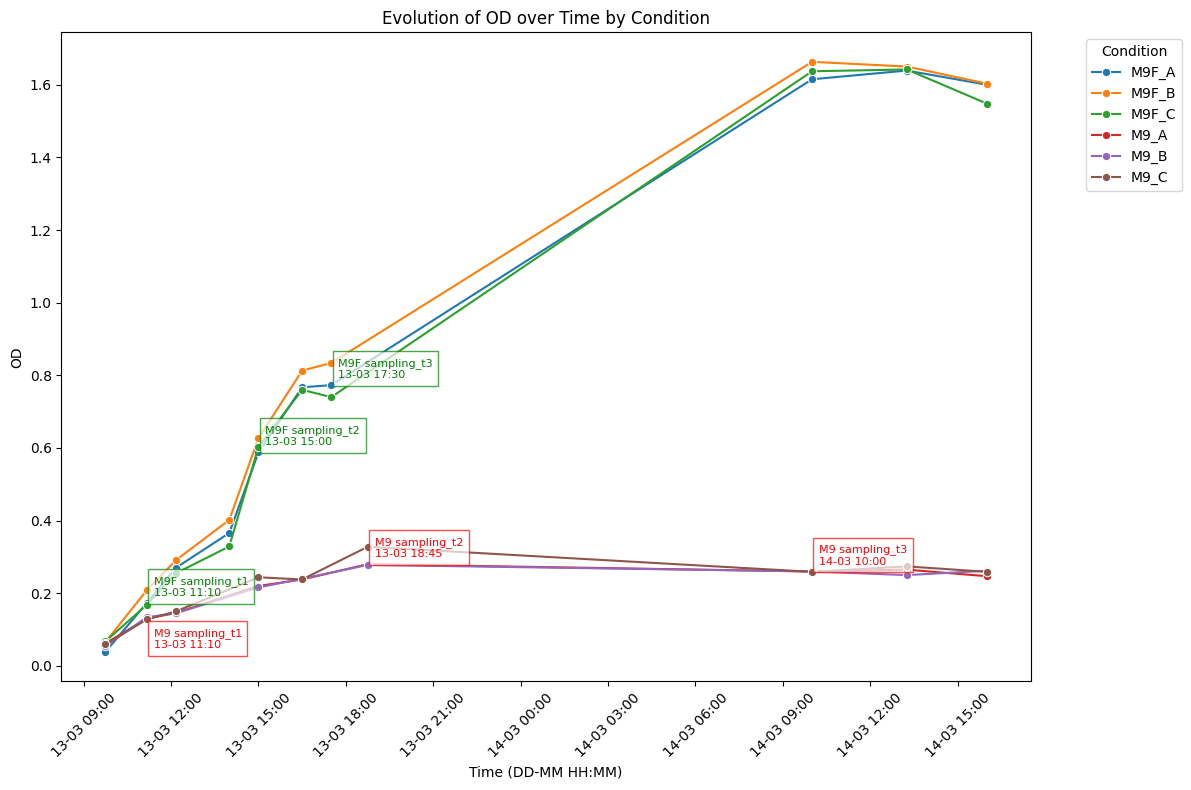

In [ ]:
# Create a time series plot showing OD evolution over time for each condition
plt.figure(figsize=(12, 8))

# Plot the main lines
sns.lineplot(data=merged_df, x="Time", y="OD", hue="Condition", marker="o")

# Add labels for points with ODt values but only for M9_A and M9F_A conditions
for idx, row in merged_df[
    (~merged_df["ODt"].isna()) & (merged_df["Condition"].isin(["M9_A", "M9F_A"]))
].iterrows():
    # Format time as DD-MM HH:MM
    time_str = row["Time"].strftime("%d-%m %H:%M")

    # Set color based on condition
    label_color = "green" if row["Condition"].startswith("M9F") else "red"

    # Map OD values to sampling labels with condition prefix
    od_value = str(row["ODt"]).strip()
    condition_prefix = "M9F" if row["Condition"].startswith("M9F") else "M9"

    if od_value == "OD1":
        sampling_label = f"{condition_prefix} sampling_t1"
    elif od_value == "OD2":
        sampling_label = f"{condition_prefix} sampling_t2"
    elif od_value == "OD3":
        sampling_label = f"{condition_prefix} sampling_t3"
    else:
        sampling_label = str(row["ODt"])

    # Set annotation position
    if sampling_label == "M9 sampling_t1":
        y_pos = 0.01  # Fixed position at 0.01
        xytext = (5, 10)  # Offset from point
    else:
        y_pos = row["OD"]
        xytext = (5, 5)

    plt.annotate(
        f"{sampling_label}\n{time_str}",
        xy=(row["Time"], y_pos),
        xytext=xytext,
        textcoords="offset points",
        fontsize=8,
        color=label_color,
        bbox=dict(facecolor="white", edgecolor=label_color, alpha=0.7),
    )

plt.title("Evolution of OD over Time by Condition")
plt.xlabel("Time (DD-MM HH:MM)")
plt.ylabel("OD")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")

# Format x-axis ticks to show date and time
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d-%m %H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()